# Podstawy sztucznej inteligencji: przestrzeń stanów, BFS, DFS, heurystyki i A*

Ten notatnik jest przeznaczony do pracy w **Google Colab**.

## Cele
Po wykonaniu notatnika student powinien:
- rozumieć pojęcie **przestrzeni stanów**,
- umieć reprezentować problem jako graf,
- rozumieć działanie **BFS** i **DFS**,
- wiedzieć, czym jest **heurystyka**,
- rozumieć funkcję $f(n) = g(n) + h(n)$ używaną w algorytmie **A\***,
- potrafić porównać BFS, DFS i A* pod względem:
  - kompletności,
  - optymalności,
  - liczby odwiedzonych stanów,
  - wykorzystania informacji o celu.


## 1. Problem jako przestrzeń stanów

W wielu klasycznych problemach AI nie pytamy od razu:

> „Jak wygląda rozwiązanie?”

Zamiast tego definiujemy:

1. **stan początkowy**,
2. **zbiór możliwych stanów**,
3. **operatory / akcje**, które zmieniają stan,
4. **test celu**,
5. opcjonalnie **koszt przejścia**.

Przykłady:
- znalezienie drogi na mapie,
- układanka 8-puzzle,
- szachy,
- planowanie działań robota,
- rozwiązanie problemu logicznego.

W tym notatniku wykorzystamy prosty świat w postaci **siatki 2D**.

- `0` – pole dostępne,
- `1` – przeszkoda,
- `S` – start,
- `G` – cel.


In [37]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math

# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1)
MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)



### Reprezentacja stanu

Stanem będzie para:

```python
(wiersz, kolumna)
```

Np. `(2, 4)` oznacza komórkę w trzecim wierszu i piątej kolumnie.

Dozwolone akcje:
- góra,
- dół,
- lewo,
- prawo.

Nie wolno:
- wyjść poza planszę,
- wejść na przeszkodę.


In [38]:

def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),  # góra
        (1, 0),   # dół
        (0, -1),  # lewo
        (0, 1),   # prawo
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors


print("Sąsiedzi startu:", get_neighbors(start))


Sąsiedzi startu: [(0, 1)]



## 2. Wizualizacja problemu


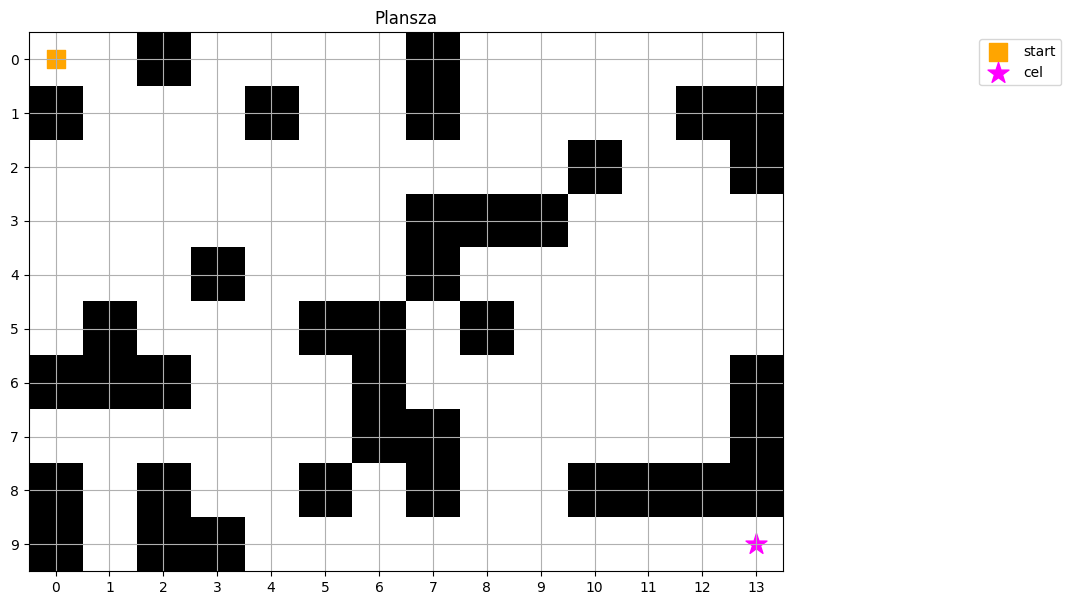

In [39]:
def draw_grid(path=None, visited=None, title="Plansza"):
    img = [[1 if cell == 0 else 0 for cell in row] for row in grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()


# 3. BFS — Breadth-First Search

BFS przeszukuje graf **warstwami**.

Najpierw:
- start,
- potem stany odległe o 1 krok,
- potem o 2 kroki,
- potem o 3 kroki,
- itd.

BFS wykorzystuje **kolejkę FIFO**.

### Ważna własność

Jeśli wszystkie przejścia mają taki sam koszt, BFS znajduje **najkrótszą ścieżkę**.

Schemat:

```text
kolejka = [start]

dopóki kolejka nie jest pusta:
    pobierz pierwszy element
    jeżeli to cel:
        zakończ
    dodaj nieodwiedzonych sąsiadów na koniec kolejki
```


BFS - długość ścieżki: 22
BFS - odwiedzone stany: 103
BFS - ścieżka: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (5, 2), (5, 3), (6, 3), (7, 3), (8, 3), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


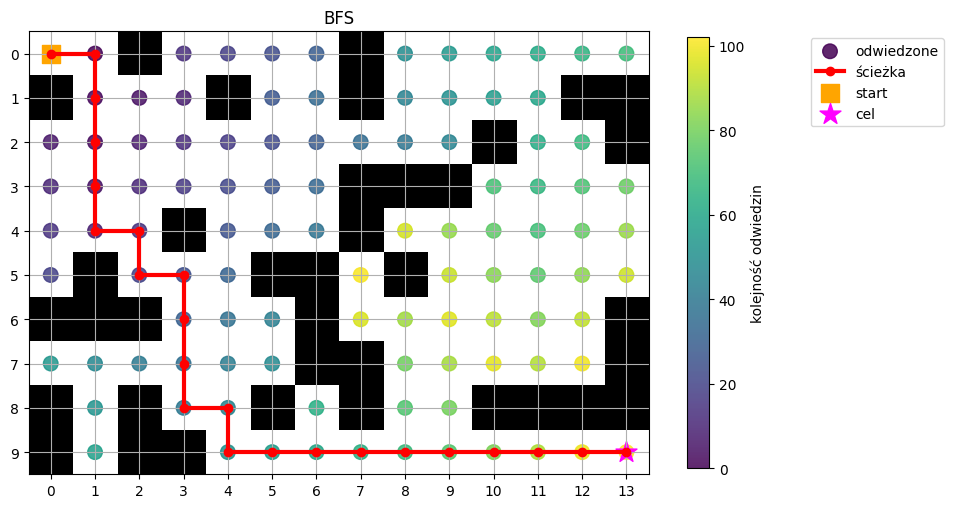

In [40]:

def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")



### Pytania

1. Dlaczego BFS używa kolejki, a nie stosu?
2. Dlaczego BFS znajduje najkrótszą ścieżkę przy jednakowych kosztach przejść?
3. Co się stanie z pamięcią BFS, gdy przestrzeń stanów będzie bardzo duża?


# 4. DFS — Depth-First Search

DFS wybiera jedną gałąź i idzie **jak najgłębiej**.

Wykorzystuje:
- stos,
- albo rekurencję.

DFS nie gwarantuje najkrótszej ścieżki.

W wersji **bez** zapamiętywania odwiedzonych stanów DFS zużywa znacznie mniej pamięci niż BFS – pamięta tylko bieżącą gałąź. W naszej implementacji (ze zbiorem `visited`) oba algorytmy mogą w najgorszym razie pamiętać wszystkie stany.

DFS - długość ścieżki: 42
DFS - odwiedzone stany: 50
DFS - ścieżka: [(0, 0), (0, 1), (1, 1), (1, 2), (1, 3), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (1, 9), (1, 10), (1, 11), (2, 11), (2, 12), (3, 12), (3, 13), (4, 13), (4, 12), (4, 11), (4, 10), (4, 9), (5, 9), (5, 10), (5, 11), (5, 12), (6, 12), (6, 11), (6, 10), (6, 9), (6, 8), (7, 8), (7, 9), (8, 9), (8, 8), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


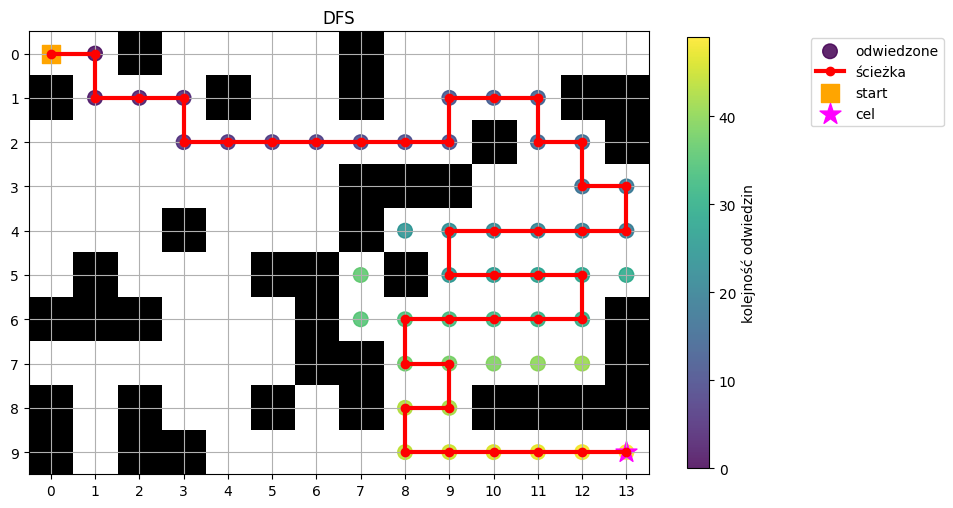

In [41]:
def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))
print("DFS - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS")

### BFS vs DFS

| Cecha | BFS | DFS |
|---|---|---|
| Struktura danych | kolejka | stos |
| Strategia | wszerz | w głąb |
| Najkrótsza ścieżka | tak, dla równych kosztów | nie |
| Kompletność | zwykle tak | zależy od przestrzeni |
| Pamięć | duża (cała „warstwa” w kolejce) | mała tylko w wersji bez zbioru odwiedzonych |
| Informacja o celu | nie | nie |

Ani BFS, ani DFS nie „wiedzą”, **w którą stronę znajduje się cel**.


# 5. Heurystyka

Heurystyka to funkcja, która próbuje oszacować:

> „Jak daleko jestem od celu?”

Zapisujemy ją jako:

$$
h(n)
$$

gdzie `n` jest aktualnym stanem.

Dobra heurystyka:
- jest szybka do policzenia,
- koreluje z rzeczywistym kosztem dojścia do celu,
- pomaga ograniczyć liczbę analizowanych stanów.

## Odległość Manhattan

Dla ruchów góra/dół/lewo/prawo:

$$
h(n) = |x_n - x_g| + |y_n - y_g|
$$


In [42]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)


examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2)
    )

(0, 0) Manhattan = 22 Euclidean = 15.81
(4, 6) Manhattan = 12 Euclidean = 8.6
(7, 10) Manhattan = 5 Euclidean = 3.61
(9, 12) Manhattan = 1 Euclidean = 1.0



### Heurystyka nie musi być idealna

Heurystyka nie rozwiązuje problemu.

Może nawet „nie widzieć” przeszkód.

Dla przykładu odległość Manhattan może wskazywać, że cel jest blisko, mimo że między stanem a celem znajduje się ściana.

Jej rolą jest **ukierunkowanie wyszukiwania**.



# 6. Greedy Best-First Search

Zanim przejdziemy do A*, zobaczmy prostszy algorytm.

Greedy Best-First Search wybiera stan z najmniejszą wartością:

$$
h(n)
$$

Czyli pyta wyłącznie:

> „Który stan wygląda na najbliższy celu?”

Nie bierze pod uwagę kosztu już przebytej drogi.


Greedy - długość ścieżki: 32
Greedy - odwiedzone stany: 37


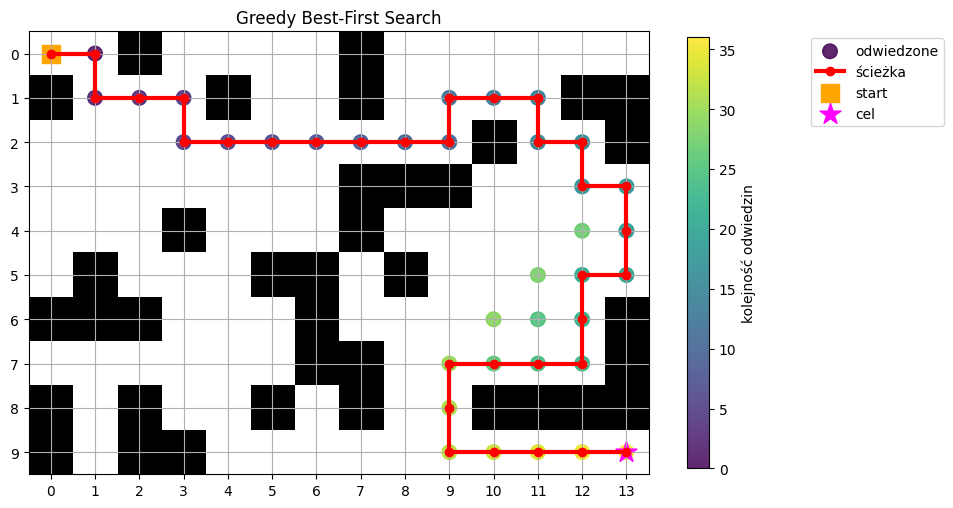

In [43]:
def greedy_best_first(start, goal):
    # W kopcu trzymamy (h, stan, rodzic) – rodzica zapisujemy przy zdjęciu z kopca,
    # tak jak w DFS.
    heap = []
    heapq.heappush(heap, (manhattan(start, goal), start, None))

    visited = set()
    parent = {}
    visit_order = []

    while heap:
        _, current, current_parent = heapq.heappop(heap)

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                heapq.heappush(
                    heap,
                    (manhattan(neighbor, goal), neighbor, current)
                )

    return None, visit_order


greedy_path, greedy_visited = greedy_best_first(start, goal)

print("Greedy - długość ścieżki:", len(greedy_path) - 1)
print("Greedy - odwiedzone stany:", len(greedy_visited))

draw_grid(greedy_path, greedy_visited, "Greedy Best-First Search")


# 7. A*

A* łączy dwie informacje.

## Koszt od startu

$$
g(n)
$$

czyli rzeczywisty koszt dojścia od startu do aktualnego stanu.

## Szacowany koszt do celu

$$
h(n)
$$

## Funkcja oceny

$$
f(n) = g(n) + h(n)
$$

A* wybiera stan o najmniejszej wartości `f(n)`.

Można to interpretować tak:

> „Szukam rozwiązania, które jest jednocześnie tanie do tej pory i wygląda obiecująco na przyszłość.”


A* - koszt: 22
A* - odwiedzone stany: 46
A* - ścieżka: [(0, 0), (0, 1), (1, 1), (1, 2), (1, 3), (2, 3), (2, 4), (3, 4), (4, 4), (5, 4), (6, 4), (7, 4), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


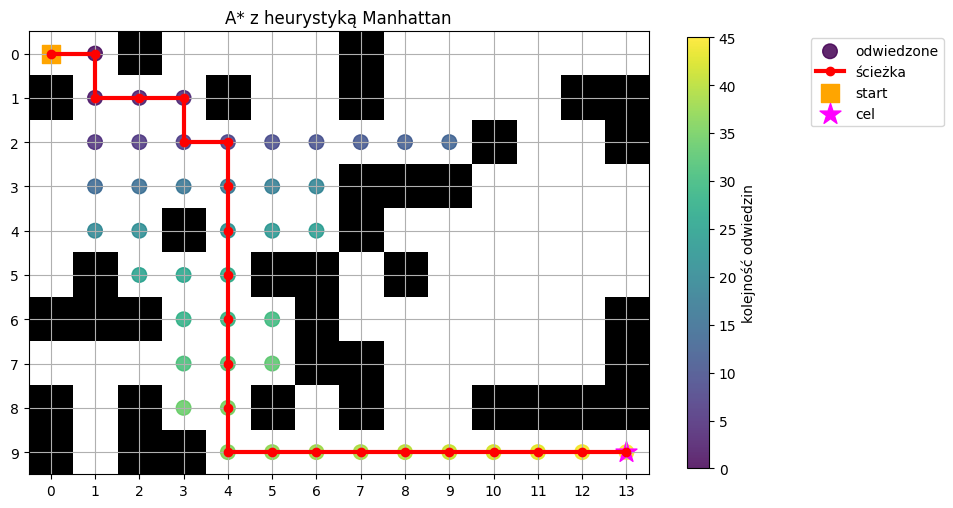

In [44]:
def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))
print("A* - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")


# 8. Porównanie algorytmów

Sprawdźmy:
- długość znalezionej ścieżki,
- liczbę odwiedzonych stanów.


In [45]:

results = [
    ("BFS", len(bfs_path) - 1, len(bfs_visited)),
    ("DFS", len(dfs_path) - 1, len(dfs_visited)),
    ("Greedy", len(greedy_path) - 1, len(greedy_visited)),
    ("A*", len(astar_path) - 1, len(astar_visited)),
]

print(f"{'Algorytm':<12} {'Długość ścieżki':<18} {'Odwiedzone stany'}")
print("-" * 50)

for name, path_len, visited_count in results:
    print(f"{name:<12} {path_len:<18} {visited_count}")


Algorytm     Długość ścieżki    Odwiedzone stany
--------------------------------------------------
BFS          22                 103
DFS          42                 50
Greedy       32                 37
A*           22                 46



## Interpretacja

Typowy wzorzec:

- **BFS** – znajduje drogę optymalną, ale może analizować wiele stanów,
- **DFS** – może szybko znaleźć rozwiązanie, ale nie musi być ono najlepsze,
- **Greedy** – mocno kieruje się ku celowi, ale może podjąć złą lokalną decyzję,
- **A\*** – łączy koszt dotychczasowy i heurystykę.

A* jest jednym z najważniejszych klasycznych algorytmów wyszukiwania w AI.


# 9. Co oznacza „dobra heurystyka”?

Dla A* szczególnie ważne jest pojęcie heurystyki **dopuszczalnej**.

Heurystyka jest dopuszczalna, jeśli nigdy nie przeszacowuje rzeczywistego kosztu dojścia do celu:

$$
h(n) \leq h^*(n)
$$

gdzie:

- $h(n)$ – nasza heurystyka,
- $h^*(n)$ – rzeczywisty minimalny koszt dojścia do celu.

Dla ruchów tylko:
- góra,
- dół,
- lewo,
- prawo,

odległość Manhattan jest naturalną heurystyką.

**Uwaga:** implementacja A* z tego notatnika (ze zbiorem `closed`, bez ponownego otwierania stanów) gwarantuje optymalność dla heurystyki **spójnej**:

$$
h(n) \leq c(n, n') + h(n')
$$

dla każdego sąsiada $n'$ stanu $n$. Każda heurystyka spójna jest dopuszczalna. Odległość Manhattan i odległość euklidesowa na naszej siatce są spójne.

In [46]:

astar_euclidean_path, astar_euclidean_visited, _ = astar(
    start,
    goal,
    heuristic=euclidean
)

print("A* Manhattan - odwiedzone stany:", len(astar_visited))
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited))


A* Manhattan - odwiedzone stany: 46
A* Euclidean - odwiedzone stany: 59



# 10. Eksperyment: A* bez heurystyki

Co się stanie, jeśli:

$$
h(n) = 0
$$

Wtedy:

$$
f(n) = g(n)
$$

A* zachowuje się wtedy jak algorytm Dijkstry.

Przy jednakowych kosztach przejść jego zachowanie jest bardzo zbliżone do BFS.


In [47]:

def zero_heuristic(a, b):
    return 0


path_h0, visited_h0, _ = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

print("A* z h=0 - odwiedzone stany:", len(visited_h0))
print("BFS       - odwiedzone stany:", len(bfs_visited))


A* z h=0 - odwiedzone stany: 103
BFS       - odwiedzone stany: 103



# 11. Eksperyment: zbyt agresywna heurystyka

Spróbujmy:

$$
h'(n) = 3 \cdot h(n)
$$

Taka heurystyka może przeszacowywać rzeczywisty koszt.

Wtedy A* może odwiedzać mniej stanów, ale traci gwarancję optymalności.


Koszt: 30
Odwiedzone stany: 41


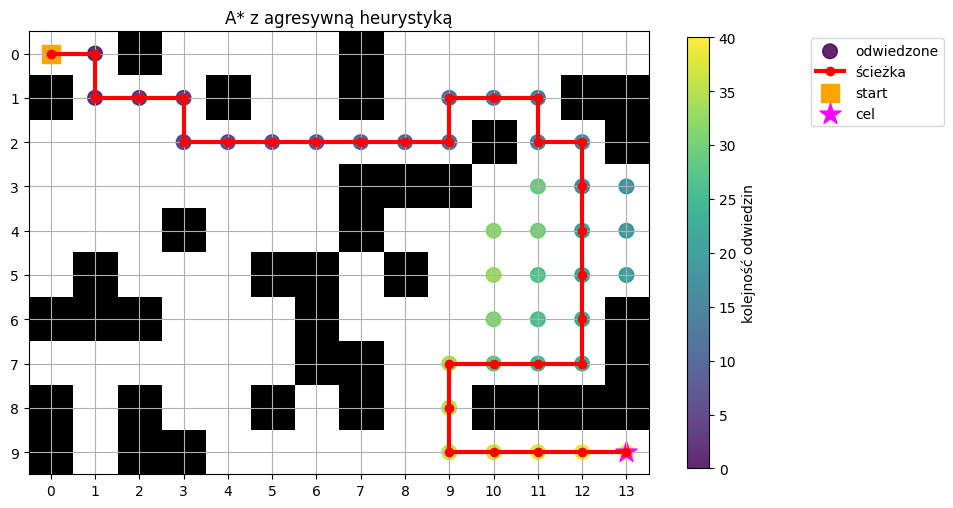

In [48]:

def aggressive_heuristic(a, b):
    return 3 * manhattan(a, b)


aggressive_path, aggressive_visited, aggressive_cost = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

print("Koszt:", aggressive_cost)
print("Odwiedzone stany:", len(aggressive_visited))

draw_grid(
    aggressive_path,
    aggressive_visited,
    "A* z agresywną heurystyką"
)


# 12. Zadania dla studentów

## Zadanie 1 — zmiana kolejności DFS

W funkcji `get_neighbors()` zmień kolejność ruchów.

Sprawdź:
- czy DFS znajdzie inną ścieżkę,
- czy zmieni się liczba odwiedzonych stanów.

Wyjaśnij dlaczego.

---

Kolejność oryginalna
Długość ścieżki: 42
Odwiedzone stany: 50

Kolejność zmieniona
Długość ścieżki: 56
Odwiedzone stany: 88

Ścieżki są różne: True


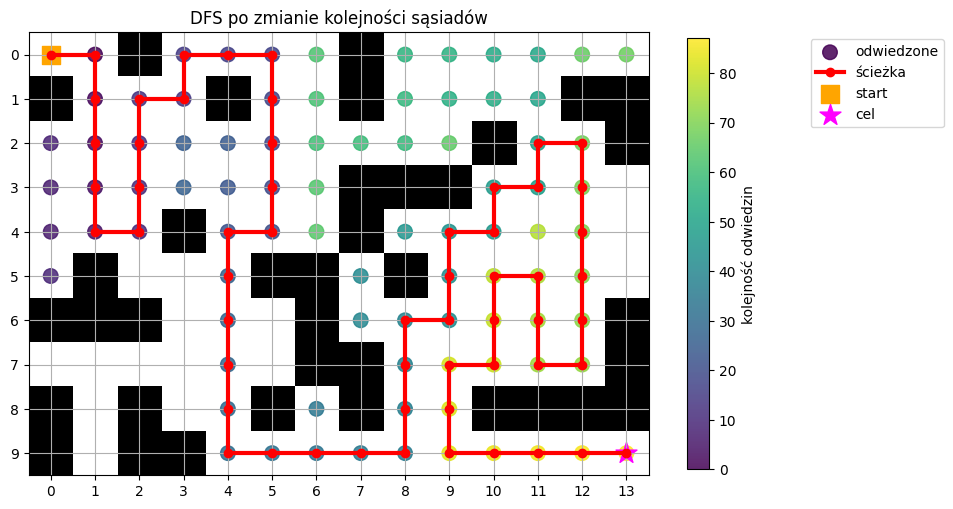

In [49]:
def get_neighbors_in_order(state, moves):
    r, c = state
    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == 0:
            neighbors.append((nr, nc))

    return neighbors


def dfs_with_order(start, goal, moves):
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors_in_order(current, moves):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


moves_original = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1),
]

moves_changed = [
    (0, 1),
    (0, -1),
    (1, 0),
    (-1, 0),
]

path_original, visited_original = dfs_with_order(start, goal, moves_original)
path_changed, visited_changed = dfs_with_order(start, goal, moves_changed)

print('Kolejność oryginalna')
print('Długość ścieżki:', len(path_original) - 1)
print('Odwiedzone stany:', len(visited_original))
print()
print('Kolejność zmieniona')
print('Długość ścieżki:', len(path_changed) - 1)
print('Odwiedzone stany:', len(visited_changed))
print()
print('Ścieżki są różne:', path_original != path_changed)

draw_grid(path_changed, visited_changed, 'DFS po zmianie kolejności sąsiadów')


## Zadanie 2 — nowa mapa

Zmodyfikuj przeszkody w `grid`.

Stwórz mapę, na której:
- BFS odwiedzi dużo stanów,
- A* odwiedzi wyraźnie mniej stanów.

---

BFS
Długość ścieżki: 22
Odwiedzone stany: 114

A-star
Długość ścieżki: 22
Koszt ścieżki: 22
Odwiedzone stany: 23


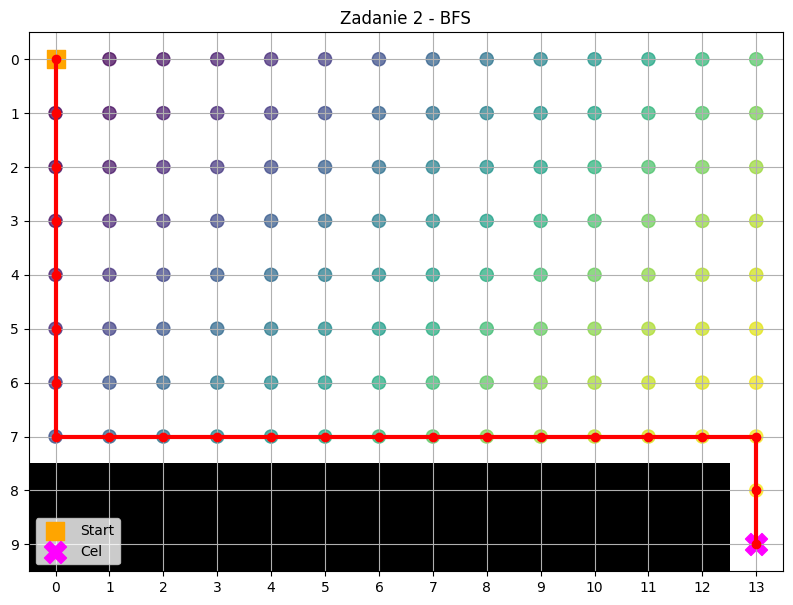

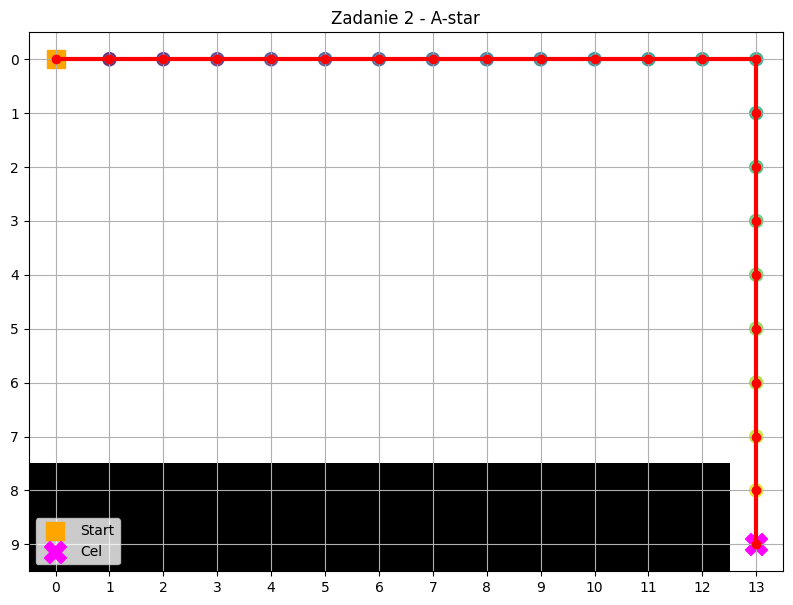

In [50]:
MAPA_ZADANIE_2 = [
    '..............',
    '..............',
    '..............',
    '..............',
    '..............',
    '..............',
    '..............',
    '..............',
    '#############.',
    '#############.',
]

grid_2 = [[1 if ch == '#' else 0 for ch in row] for row in MAPA_ZADANIE_2]
start_2 = (0, 0)
goal_2 = (9, 13)
rows_2 = len(grid_2)
cols_2 = len(grid_2[0])


def neighbors_2(state):
    r, c = state
    result = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows_2 and 0 <= nc < cols_2 and grid_2[nr][nc] == 0:
            result.append((nr, nc))
    return result


def bfs_2(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    order = []

    while queue:
        current = queue.popleft()
        order.append(current)
        if current == goal:
            return reconstruct_path(parent, goal), order

        for neighbor in neighbors_2(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, order


def astar_2(start, goal):
    heap = []
    start_h = manhattan(start, goal)
    heapq.heappush(heap, (start_h, start_h, start))
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    order = []

    while heap:
        _, _, current = heapq.heappop(heap)
        if current in closed:
            continue

        closed.add(current)
        order.append(current)
        if current == goal:
            return reconstruct_path(parent, goal), order, g_score[goal]

        for neighbor in neighbors_2(current):
            tentative_g = g_score[current] + 1
            if tentative_g < g_score.get(neighbor, float('inf')):
                g_score[neighbor] = tentative_g
                parent[neighbor] = current
                h = manhattan(neighbor, goal)
                heapq.heappush(heap, (tentative_g + h, h, neighbor))

    return None, order, float('inf')


bfs_path_2, bfs_visited_2 = bfs_2(start_2, goal_2)

astar_path_2, astar_visited_2, astar_cost_2 = astar_2(
    start_2,
    goal_2
)

print("BFS")
print("Długość ścieżki:", len(bfs_path_2) - 1)
print("Odwiedzone stany:", len(bfs_visited_2))
print()

print("A-star")
print("Długość ścieżki:", len(astar_path_2) - 1)
print("Koszt ścieżki:", astar_cost_2)
print("Odwiedzone stany:", len(astar_visited_2))


def draw_grid_2(path=None, visited=None, title="Plansza"):
    img = [
        [1 if cell == 0 else 0 for cell in row]
        for row in grid_2
    ]

    plt.figure(figsize=(10, 7))
    plt.imshow(
        img,
        cmap="gray",
        origin="upper"
    )

    if visited:
        visited_rows = [state[0] for state in visited]
        visited_cols = [state[1] for state in visited]

        plt.scatter(
            visited_cols,
            visited_rows,
            c=range(len(visited)),
            cmap="viridis",
            s=90,
            alpha=0.75
        )

    if path:
        path_rows = [state[0] for state in path]
        path_cols = [state[1] for state in path]

        plt.plot(
            path_cols,
            path_rows,
            color="red",
            marker="o",
            linewidth=3
        )

    plt.scatter(
        start_2[1],
        start_2[0],
        s=180,
        marker="s",
        color="orange",
        label="Start"
    )

    plt.scatter(
        goal_2[1],
        goal_2[0],
        s=250,
        marker="X",
        color="magenta",
        label="Cel"
    )

    plt.xticks(range(cols_2))
    plt.yticks(range(rows_2))
    plt.grid(True)
    plt.legend()
    plt.title(title)
    plt.show()


draw_grid_2(
    bfs_path_2,
    bfs_visited_2,
    "Zadanie 2 - BFS"
)

draw_grid_2(
    astar_path_2,
    astar_visited_2,
    "Zadanie 2 - A-star"
)

## Zadanie 3 — własna heurystyka

Napisz heurystykę:

```python
def my_heuristic(a, b):
    ...
```

Porównaj ją z:
- Manhattan,
- Euclidean,
- `h(n)=0`.

---


Heurystyka          Długość     Koszt       Odwiedzone stany
-----------------------------------------------------------------
h = 0               22          22          103
Własna heurystyka   22          22          69
Euklidesowa         22          22          59
Manhattan           22          22          46

Wynik własnej heurystyki
Długość ścieżki: 22
Koszt ścieżki: 22
Odwiedzone stany: 69


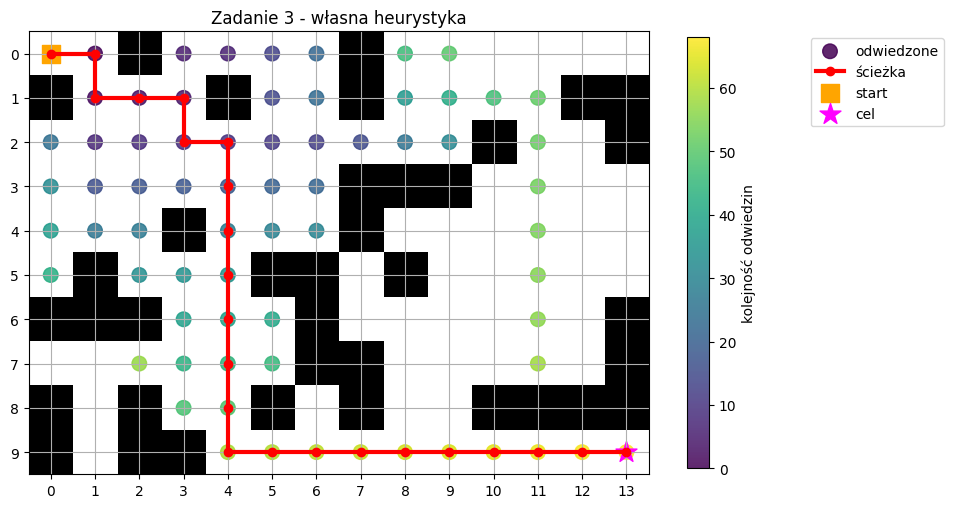

In [51]:
def my_heuristic(a, b):
    row_distance = abs(a[0] - b[0])
    col_distance = abs(a[1] - b[1])

    return max(row_distance, col_distance)


heuristics_task_3 = [
    ("h = 0", zero_heuristic),
    ("Własna heurystyka", my_heuristic),
    ("Euklidesowa", euclidean),
    ("Manhattan", manhattan)
]

results_task_3 = []

for name, heuristic in heuristics_task_3:
    path, visited, cost = astar(
        start,
        goal,
        heuristic=heuristic
    )

    results_task_3.append(
        (
            name,
            len(path) - 1,
            cost,
            len(visited)
        )
    )


print(
    f"{'Heurystyka':<20}"
    f"{'Długość':<12}"
    f"{'Koszt':<12}"
    f"{'Odwiedzone stany'}"
)

print("-" * 65)

for name, path_length, cost, visited_count in results_task_3:
    print(
        f"{name:<20}"
        f"{path_length:<12}"
        f"{cost:<12}"
        f"{visited_count}"
    )


my_path, my_visited, my_cost = astar(
    start,
    goal,
    heuristic=my_heuristic
)

print()
print("Wynik własnej heurystyki")
print("Długość ścieżki:", len(my_path) - 1)
print("Koszt ścieżki:", my_cost)
print("Odwiedzone stany:", len(my_visited))

draw_grid(
    my_path,
    my_visited,
    "Zadanie 3 - własna heurystyka"
)

## Zadanie 4 — ruch po przekątnej

Dodaj ruchy:

```text
↖ ↑ ↗
←   →
↙ ↓ ↘
```

Odpowiedz:

1. Czy Manhattan nadal jest najlepszym wyborem?
2. Jaką heurystykę zastosować?
3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?

---

Ruch ukośny o koszcie 1
Długość ścieżki: 20
Koszt: 20.0
Odwiedzone stany: 81

Ruch ukośny o koszcie sqrt(2)
Długość ścieżki: 20
Koszt: 20.828
Odwiedzone stany: 59


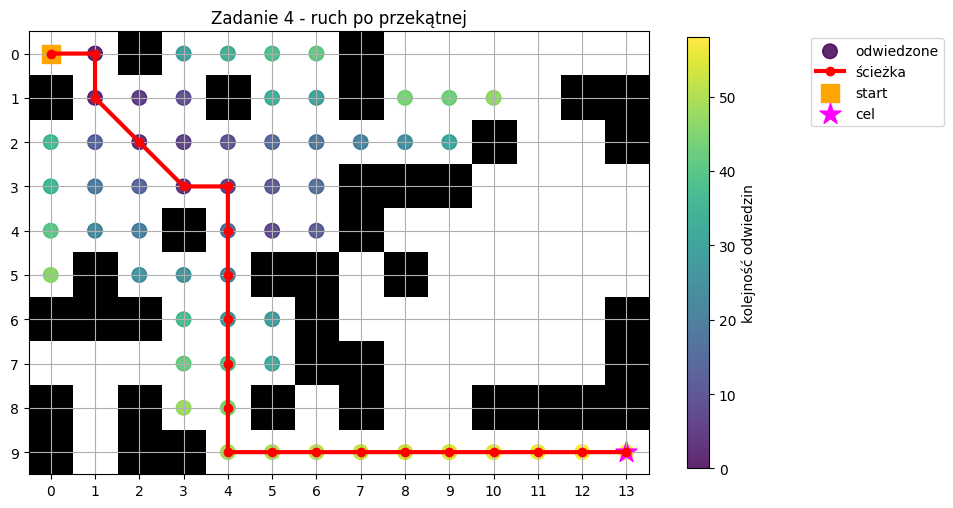

In [52]:
def diagonal_neighbors(state, diagonal_cost=1.0):
    r, c = state
    moves = [
        (-1, 0, 1.0),
        (1, 0, 1.0),
        (0, -1, 1.0),
        (0, 1, 1.0),
        (-1, -1, diagonal_cost),
        (-1, 1, diagonal_cost),
        (1, -1, diagonal_cost),
        (1, 1, diagonal_cost),
    ]
    result = []

    for dr, dc, move_cost in moves:
        nr, nc = r + dr, c + dc

        if not (0 <= nr < rows and 0 <= nc < cols):
            continue
        if grid[nr][nc] == 1:
            continue

        # Ruch ukośny nie może przecinać narożnika przeszkody.
        if dr != 0 and dc != 0:
            if grid[r][nc] == 1 or grid[nr][c] == 1:
                continue

        result.append(((nr, nc), move_cost))

    return result


def astar_diagonal(start, goal, diagonal_cost, heuristic):
    heap = []
    counter = 0
    heapq.heappush(heap, (heuristic(start, goal), counter, start))
    g_score = {start: 0.0}
    parent = {start: None}
    closed = set()
    order = []

    while heap:
        _, _, current = heapq.heappop(heap)
        if current in closed:
            continue

        closed.add(current)
        order.append(current)
        if current == goal:
            return reconstruct_path(parent, goal), order, g_score[goal]

        for neighbor, move_cost in diagonal_neighbors(current, diagonal_cost):
            tentative_g = g_score[current] + move_cost
            if tentative_g < g_score.get(neighbor, float('inf')):
                g_score[neighbor] = tentative_g
                parent[neighbor] = current
                counter += 1
                heapq.heappush(
                    heap,
                    (tentative_g + heuristic(neighbor, goal), counter, neighbor)
                )

    return None, order, float('inf')


path_diagonal_1, visited_diagonal_1, cost_diagonal_1 = astar_diagonal(
    start,
    goal,
    diagonal_cost=1.0,
    heuristic=my_heuristic
)

path_diagonal_sqrt, visited_diagonal_sqrt, cost_diagonal_sqrt = astar_diagonal(
    start, goal, diagonal_cost=math.sqrt(2), heuristic=euclidean
)

print('Ruch ukośny o koszcie 1')
print('Długość ścieżki:', len(path_diagonal_1) - 1)
print('Koszt:', round(cost_diagonal_1, 3))
print('Odwiedzone stany:', len(visited_diagonal_1))
print()
print('Ruch ukośny o koszcie sqrt(2)')
print('Długość ścieżki:', len(path_diagonal_sqrt) - 1)
print('Koszt:', round(cost_diagonal_sqrt, 3))
print('Odwiedzone stany:', len(visited_diagonal_sqrt))

draw_grid(path_diagonal_sqrt, visited_diagonal_sqrt, 'Zadanie 4 - ruch po przekątnej')


## Zadanie 5 — przeszkody z różnym kosztem

Załóż, że wejście na:
- zwykłe pole kosztuje `1`,
- piasek kosztuje `3`,
- bagno kosztuje `5`.

Zmodyfikuj A*, aby uwzględniał różne koszty przejść.

Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki?

---

Rozmiar mapy: 10 x 14
Długość ścieżki: 22
Łączny koszt: 32
Odwiedzone stany: 100
Ścieżka: [(0, 0), (0, 1), (1, 1), (1, 2), (2, 2), (3, 2), (3, 3), (3, 4), (4, 4), (5, 4), (6, 4), (7, 4), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


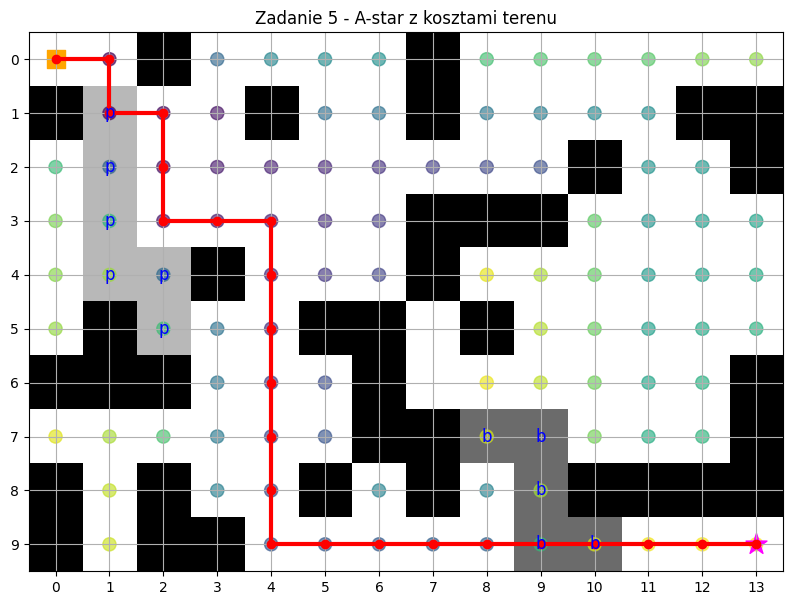

In [53]:
# Oryginalna mapa zachowuje rozmiar 10 x 14 i położenie przeszkód.
terrain_grid = [list(row) for row in MAPA]

# p - piasek, koszt 3
# b - bagno, koszt 5
sand_fields = [(1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (5, 2)]
mud_fields = [(7, 8), (7, 9), (8, 9), (9, 9), (9, 10)]

for r, c in sand_fields:
    if terrain_grid[r][c] == '.':
        terrain_grid[r][c] = 'p'

for r, c in mud_fields:
    if terrain_grid[r][c] == '.':
        terrain_grid[r][c] = 'b'


def terrain_cost(state):
    r, c = state
    field = terrain_grid[r][c]
    if field == 'p':
        return 3
    if field == 'b':
        return 5
    return 1


def terrain_neighbors(state):
    r, c = state
    result = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and terrain_grid[nr][nc] != '#':
            result.append((nr, nc))
    return result


def astar_weighted(start, goal):
    heap = []
    counter = 0
    heapq.heappush(heap, (manhattan(start, goal), counter, start))
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    order = []

    while heap:
        _, _, current = heapq.heappop(heap)
        if current in closed:
            continue

        closed.add(current)
        order.append(current)
        if current == goal:
            return reconstruct_path(parent, goal), order, g_score[goal]

        for neighbor in terrain_neighbors(current):
            tentative_g = g_score[current] + terrain_cost(neighbor)
            if tentative_g < g_score.get(neighbor, float('inf')):
                g_score[neighbor] = tentative_g
                parent[neighbor] = current
                counter += 1
                heapq.heappush(
                    heap,
                    (tentative_g + manhattan(neighbor, goal), counter, neighbor)
                )

    return None, order, float('inf')


weighted_path, weighted_visited, weighted_cost = astar_weighted(start, goal)

print('Rozmiar mapy:', len(terrain_grid), 'x', len(terrain_grid[0]))
print('Długość ścieżki:', len(weighted_path) - 1)
print('Łączny koszt:', weighted_cost)
print('Odwiedzone stany:', len(weighted_visited))
print('Ścieżka:', weighted_path)


def draw_terrain(path=None, visited=None, title='Różne koszty pól'):
    values = {'.': 1, 'p': 0.72, 'b': 0.42, '#': 0}
    img = [[values[cell] for cell in row] for row in terrain_grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap='gray', origin='upper', vmin=0, vmax=1)

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        plt.scatter(vc, vr, c=range(len(visited)), cmap='viridis', s=90, alpha=0.65)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color='red', marker='o', linewidth=3)

    for r in range(rows):
        for c in range(cols):
            if terrain_grid[r][c] in ('p', 'b'):
                plt.text(c, r, terrain_grid[r][c], ha='center', va='center', color='blue', fontsize=12)

    plt.scatter(start[1], start[0], s=180, marker='s', color='orange')
    plt.scatter(goal[1], goal[0], s=250, marker='*', color='magenta')
    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.show()


draw_terrain(weighted_path, weighted_visited, 'Zadanie 5 - A-star z kosztami terenu')


## Zadanie 6 - różnica między `g(n)` i `h(n)`

`g(n)` jest rzeczywistym kosztem przejścia od stanu początkowego do stanu `n`.  
`h(n)` jest oszacowaniem kosztu pozostałego od stanu `n` do celu.  
Algorytm A-star porównuje stany za pomocą `f(n) = g(n) + h(n)`, dlatego uwzględnia zarówno koszt już przebytej drogi, jak i przewidywany koszt dalszej części trasy.


# 13. Zadanie rozszerzone — 8-puzzle

Rozważ układankę:

```text
_ 2 4
3 6 5
7 1 8
```

Stan można zapisać jako:

```python
(0, 2, 4,
 3, 6, 5,
 7, 1, 8)
```

gdzie `0` oznacza puste pole.

Stan docelowy:

```python
(1, 2, 3,
 4, 5, 6,
 7, 8, 0)
```

### Zadanie

Zaimplementuj A* dla 8-puzzle.

Jako heurystykę wykorzystaj:

> sumę odległości Manhattan każdego kafelka od jego pozycji docelowej.

To klasyczny przykład problemu przeszukiwania przestrzeni stanów.

In [54]:
# Miejsce na rozwiązanie zadania 8-puzzle.

start_puzzle = (
    0, 2, 4,
    3, 6, 5,
    7, 1, 8
)

goal_puzzle = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

# TODO:
# 1. napisz funkcję generującą sąsiadów,
# 2. napisz heurystykę Manhattan,
# 3. wykorzystaj A*.

# 14. Podsumowanie

Najważniejsze idee:

### Przestrzeń stanów
Problem AI można traktować jako zbiór stanów połączonych możliwymi akcjami.

### BFS
Przeszukuje wszerz i dla jednakowych kosztów gwarantuje najkrótszą ścieżkę.

### DFS
Przeszukuje w głąb i nie gwarantuje najlepszego rozwiązania. W wersji bez zapamiętywania odwiedzonych stanów potrzebuje znacznie mniej pamięci niż BFS.

### Heurystyka
Dostarcza dodatkowej wiedzy o tym, które stany wyglądają obiecująco.

### A*
Łączy:

$$
g(n)
$$

oraz

$$
h(n)
$$

w funkcji:

$$
f(n)=g(n)+h(n)
$$

Dzięki temu może znajdować optymalne rozwiązania znacznie bardziej efektywnie niż algorytmy niepoinformowane.


# 15. Pytania kontrolne

1. Co jest stanem w problemie wyszukiwania drogi?
2. Czym różni się BFS od DFS?
3. Dlaczego BFS może potrzebować dużo pamięci?
4. Co oznacza $g(n)$?
5. Co oznacza $h(n)$?
6. Co oznacza $f(n)$?
7. Dlaczego heurystyka może przyspieszyć wyszukiwanie?
8. Co oznacza, że heurystyka jest dopuszczalna?
9. Co się stanie w A*, gdy $h(n)=0$?
10. Czy A* zawsze jest szybszy od BFS?
